# Clothing Classification (Fashion MNIST)

Same idea as MNIST but harder: 28x28 grayscale pictures of 10 kinds of clothes.
I tried two different CNNs and compared them.

In [42]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Conv2D, MaxPool2D, Flatten, Dropout, BatchNormalization
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import classification_report, confusion_matrix

## Loading the data

In [43]:
from tensorflow.keras.datasets import fashion_mnist

(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

labels = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
          'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

print(X_train.shape, y_train.shape)
print(X_test.shape, y_test.shape)

(60000, 28, 28) (60000,)
(10000, 28, 28) (10000,)


## Looking at the data

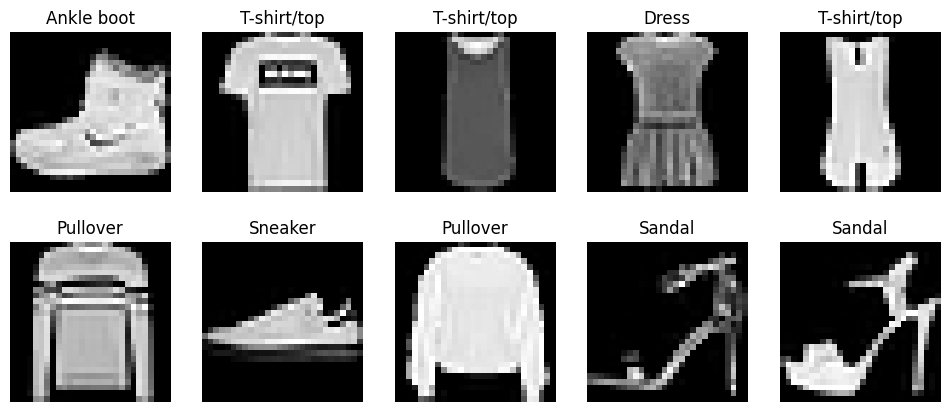

In [44]:
plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap='gray')
    plt.title(labels[y_train[i]])
    plt.axis('off')
plt.show()

## Preprocessing

In [45]:
X_train = X_train.astype('float32') / 255
X_test = X_test.astype('float32') / 255

X_train = X_train.reshape(60000, 28, 28, 1)
X_test = X_test.reshape(10000, 28, 28, 1)

y_train_new = to_categorical(y_train)
y_test_new = to_categorical(y_test)

## Model 1

Two conv layers and two big dense layers with dropout.

In [46]:
model = Sequential()
model.add(Input(shape=(28, 28, 1)))
model.add(Conv2D(filters=32, kernel_size=(4, 4), activation='relu'))
model.add(MaxPool2D(pool_size=(2, 2)))
model.add(Conv2D(filters=32, kernel_size=(4, 4), activation='relu'))
model.add(MaxPool2D(pool_size=(2, 2)))
model.add(Flatten())
model.add(Dense(784, activation='relu'))
model.add(Dropout(0.4))
model.add(Dense(392, activation='relu'))
model.add(Dropout(0.4))
model.add(Dense(10, activation='softmax'))
model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 25, 25, 32)     │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 12, 12, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 9, 9, 32)       │        16,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 4, 4, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 784)            │       402,192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 392)            │       307,720 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 392)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │         3,930 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 730,802 (2.79 MB)

 Trainable params: 730,802 (2.79 MB)

 Non-trainable params: 0 (0.00 B)

In [47]:
earlystop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

history = model.fit(X_train, y_train_new,
                    epochs=20,
                    validation_split=0.1,
                    callbacks=[earlystop])

Epoch 1/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 78s 44ms/step - accuracy: 0.8054 - loss: 0.5260 - val_accuracy: 0.8737 - val_loss: 0.3453
Epoch 2/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 60s 36ms/step - accuracy: 0.8732 - loss: 0.3493 - val_accuracy: 0.8862 - val_loss: 0.3138
Epoch 3/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 83s 37ms/step - accuracy: 0.8877 - loss: 0.3074 - val_accuracy: 0.8705 - val_loss: 0.3521
Epoch 4/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 60s 35ms/step - accuracy: 0.8952 - loss: 0.2813 - val_accuracy: 0.8948 - val_loss: 0.2882
Epoch 5/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 61s 36ms/step - accuracy: 0.9029 - loss: 0.2607 - val_accuracy: 0.8978 - val_loss: 0.2742
Epoch 6/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 60s 35ms/step - accuracy: 0.9074 - loss: 0.2448 - val_accuracy: 0.8988 - val_loss: 0.2753
Epoch 7/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 59s 35ms/step - accuracy: 0.9145 - loss: 0.2269 - val_accuracy: 0.8973 - val_loss: 0.2786
Epoch 8/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 84s 37ms/step - accuracy: 0.9175 -

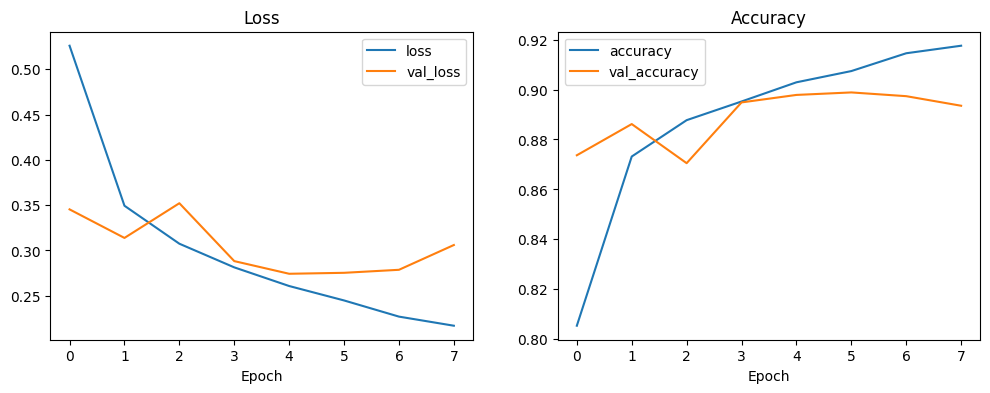

In [48]:
losses = pd.DataFrame(history.history)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
losses[['loss', 'val_loss']].plot(ax=ax[0], title='Loss')
losses[['accuracy', 'val_accuracy']].plot(ax=ax[1], title='Accuracy')
ax[0].set_xlabel('Epoch')
ax[1].set_xlabel('Epoch')
plt.show()

## Model 2

`padding='same'`, more filters in the second layer, BatchNormalization after each conv layer and a smaller dense layer.

In [49]:
model1 = Sequential()
model1.add(Input(shape=(28, 28, 1)))
model1.add(Conv2D(filters=32, kernel_size=(3, 3), padding='same', activation='relu'))
model1.add(BatchNormalization())
model1.add(MaxPool2D(pool_size=(2, 2)))
model1.add(Conv2D(filters=64, kernel_size=(3, 3), padding='same', activation='relu'))
model1.add(BatchNormalization())
model1.add(MaxPool2D(pool_size=(2, 2)))
model1.add(Flatten())
model1.add(Dense(128, activation='relu'))
model1.add(Dropout(0.4))
model1.add(Dense(10, activation='softmax'))
model1.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

model1.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 422,026 (1.61 MB)

 Trainable params: 421,834 (1.61 MB)

 Non-trainable params: 192 (768.00 B)

In [50]:

earlystop1 = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

history1 = model1.fit(X_train, y_train_new,
                      epochs=20,
                      validation_split=0.1,
                      callbacks=[earlystop1])

Epoch 1/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 102s 60ms/step - accuracy: 0.8268 - loss: 0.4925 - val_accuracy: 0.8830 - val_loss: 0.3091
Epoch 2/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 102s 60ms/step - accuracy: 0.8749 - loss: 0.3451 - val_accuracy: 0.8968 - val_loss: 0.2776
Epoch 3/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 100s 59ms/step - accuracy: 0.8919 - loss: 0.2952 - val_accuracy: 0.9062 - val_loss: 0.2413
Epoch 4/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 102s 60ms/step - accuracy: 0.9018 - loss: 0.2667 - val_accuracy: 0.9073 - val_loss: 0.2529
Epoch 5/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 101s 60ms/step - accuracy: 0.9101 - loss: 0.2476 - val_accuracy: 0.9173 - val_loss: 0.2399
Epoch 6/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 102s 60ms/step - accuracy: 0.9153 - loss: 0.2302 - val_accuracy: 0.9177 - val_loss: 0.2318
Epoch 7/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 140s 60ms/step - accuracy: 0.9233 - loss: 0.2086 - val_accuracy: 0.9157 - val_loss: 0.2614
Epoch 8/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 102s 61ms/step - accuracy: 

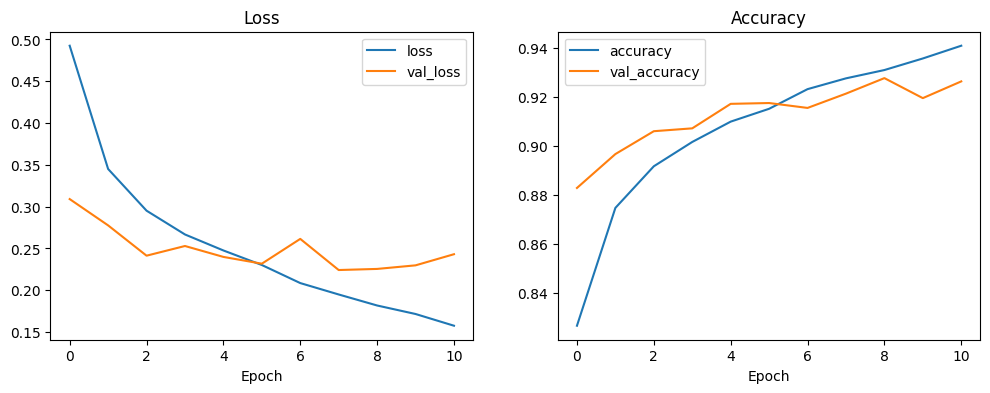

In [51]:
losses = pd.DataFrame(history1.history)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
losses[['loss', 'val_loss']].plot(ax=ax[0], title='Loss')
losses[['accuracy', 'val_accuracy']].plot(ax=ax[1], title='Accuracy')
ax[0].set_xlabel('Epoch')
ax[1].set_xlabel('Epoch')
plt.show()

## Comparing the two models on the test set

In [52]:
loss_1, acc_1 = model.evaluate(X_test, y_test_new, verbose=0)
loss_2, acc_2 = model1.evaluate(X_test, y_test_new, verbose=0)

print('Model 1 test accuracy:', round(acc_1, 4), ' epochs:', len(history.history['loss']))
print('Model 2 test accuracy:', round(acc_2, 4), ' epochs:', len(history1.history['loss']))

Model 1 test accuracy: 0.8906  epochs: 8
Model 2 test accuracy: 0.917  epochs: 11


In [53]:

if acc_2 >= acc_1:
    best_model, best_name = model1, 'Model 2'
else:
    best_model, best_name = model, 'Model 1'

print('Best model:', best_name)

Best model: Model 2


In [54]:
predictions = best_model.predict(X_test).argmax(axis=-1)

print(classification_report(y_test, predictions, target_names=labels))

313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step
              precision    recall  f1-score   support

 T-shirt/top       0.89      0.84      0.86      1000
     Trouser       1.00      0.98      0.99      1000
    Pullover       0.85      0.90      0.88      1000
       Dress       0.90      0.94      0.92      1000
        Coat       0.86      0.89      0.87      1000
      Sandal       0.99      0.98      0.98      1000
       Shirt       0.77      0.71      0.74      1000
     Sneaker       0.97      0.96      0.97      1000
         Bag       0.98      0.98      0.98      1000
  Ankle boot       0.96      0.97      0.97      1000

    accuracy                           0.92     10000
   macro avg       0.92      0.92      0.92     10000
weighted avg       0.92      0.92      0.92     10000



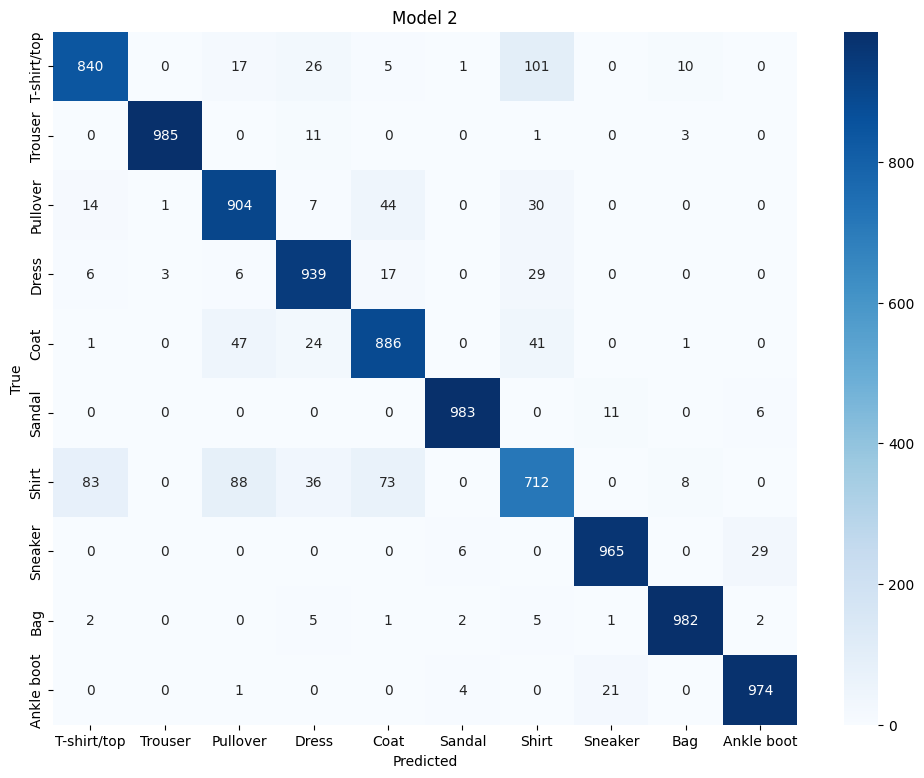

In [55]:
plt.figure(figsize=(12, 9))
sns.heatmap(confusion_matrix(y_test, predictions), cmap='Blues', annot=True, fmt='d',
            xticklabels=labels, yticklabels=labels)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title(best_name)
plt.show()

Shirt, T-shirt, Pullover and Coat look a lot alike, so most of the mistakes are between them.

## Predicting a single image

In [56]:
def img_name(index):
    img = X_test[index]
    index_pred = best_model.predict(img.reshape(1, 28, 28, 1), verbose=0).argmax(axis=-1)[0]
    plt.imshow(img.reshape(28, 28), cmap='gray')
    plt.title(f'Predicted: {labels[index_pred]}   True: {labels[y_test[index]]}')
    plt.axis('off')
    plt.show()

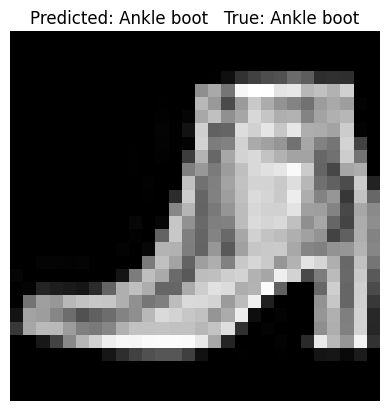

In [57]:
img_name(537)

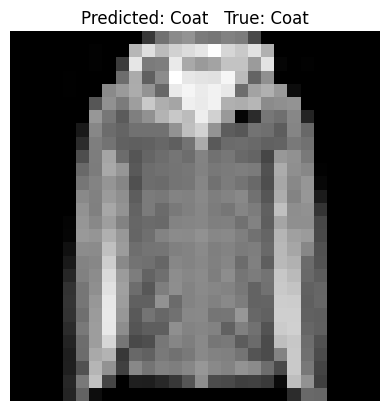

In [58]:
img_name(7544)

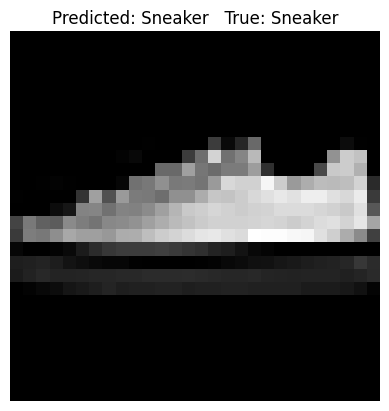

In [59]:
img_name(5800)

## Saving the models

In [60]:
model.save('fashion_mnist_model1.keras')
model1.save('fashion_mnist_model2.keras')